# North Anatolian fault creep: a conditional subsurface image


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `anatolian_fault_creep_distribution` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：fault_triangles (1, 1292, 3, 3) float64：Known main-fault vertices; last axis east,north,positive-down depth in km；deep_rectangles (1, 5, 4, 3) float64：Known deep-fault vertices in km, same coordinate convention；remote_rectangles (1, 2, 4, 3) float64：Known east then west fault vertices in km；sar_xy (1, 3476, 2) float64：Radar observation east/north coordinates in km；sar_los (1, 3476, 3) float64：Dimensionless east,north,up line-of-sight projection vectors；sar_velocity (1, 3476) float64：Curated radar line-of-sight velocities in mm/year；sar_track_index (1, 3476) int32：Dimensionless track labels0,1,2 for87,65,167；sar_lonlat (1, 3476, 2) float64：Radar longitude/latitude in degrees；gnss_xy (1, 39, 2) float64：Ground-station east/north coordinates in km；gnss_lonlat (1, 39, 2) float64：Ground-station longitude/latitude in degrees；gnss_velocity (1, 39, 2) float64：Curated ground-station east/north velocities in mm/year；gnss_std (1, 39, 2) float64：Ground-station east/north standard deviations in mm/year。恢复目标：1299断层滑动率、盆地下沉系数与5个速度datum。

获取模型：弹性半空间Green函数经LOS投影，将滑移与经验盆地项映射为SAR/GNSS速度。实际恢复算法：solvers.assemble_problem/solve_system/reconstruct；相关噪声GLS/NNLS及深部共享参数。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:11/201明确原始方法参考，不是独立地下滑移真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：anatolian_fault_creep_distribution.ipynb单元3有保存图；ax.quiverkey(q,.17,.9,5.,'5 mm/year',coordinates='axes',labelpos='S');ax.set(xlabel='East (km)',ylabel='North (km)',title='B. All 39 real GNSS vectors');ax.set_aspect('equal')；axes；anatolian_fault_creep_distribution.ipynb单元5有保存图；图内容由该单元调用的本地visualization函数生成；anatolian_fault_creep_distribution.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；anatolian_fault_creep_distribution.ipynb单元8：5. Results: fitted observations, complete outputs and strict evaluation；anatolian_fault_creep_distribution.ipynb单元9有保存图；axes[3,0].quiverkey(q,.17,.9,5.,'5 mm/year',coordinates='axes',labelpos='S');axes[3,0].legend();axes[3,0].set_title('All 39 GNSS sites')；axes[3,1].quiverkey(q,.17,.9,1.,'1 mm/year'；anatolian_fault_creep_distribution.ipynb单元10：6. Sensitivity and conclusion: a conditional image, not hidden truth；anatolian_fault_creep_distribution.ipynb单元11有保存图；axes[1,2].set(xlabel='Noise-weighted RMS on original observations',ylabel='RMS main-slip change (mm/year)',title='Assumption dependence at complete-field scale');axes[1,2].legend(f。图/比较代码位于单元1, 3, 5, 7, 9, 11（从0计数）。代码单元6个，带execution_count的6个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


This notebook actively reconstructs all1,299slip rates and all six nuisance
coefficients from the bound real author-curated LOS/GNSS velocities. Original
author runs, fresh local reconstructions and new sensitivity measurements are
identified separately. The method reference is not subsurface truth.

## 1. Problem: ground velocities constrain buried slip

Slow fault creep produces broad elastic surface motion. Three satellite
viewing directions and horizontal GNSS vectors constrain its distribution,
but correlated noise, depth-dependent sensitivity and nuisance motion create
tradeoffs. We select the author's simplified homogeneous-half-space tutorial
and its final tied-deep NNLS estimate. The article's layered-medium posterior
and time-dependent slow-event analysis are different experiments.

In [1]:
from pathlib import Path
import os,sys,json,time,hashlib,subprocess
import numpy as np,scipy,matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize,TwoSlopeNorm
from scipy.linalg import cho_factor,cho_solve
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,observation_vector,SAR_COUNTS,NOISE_SIGMA,NOISE_LENGTH_KM,NOISE_STD
from src.physics_model import build_data_covariance
from src.solvers import assemble_problem,solve_system,output_arrays
from src.generate_data import correlated_velocity_perturbation
from src.visualization import reference_metrics,signed_norm,fault_panel,scatter_panel,save_figure,vector_extent
FIGDIR=Path(os.environ['IMAGING_FIGURE_DIR']) if os.environ.get('IMAGING_FIGURE_DIR') else None
if FIGDIR:FIGDIR.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':9,'axes.titlesize':10,'figure.dpi':100,'axes.grid':False})
environment={'executable':sys.executable,'python':sys.version,'numpy':np.__version__,'scipy':scipy.__version__,
 'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),
 'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']},
 'numpy_config':np.show_config(mode='dicts')}
print(json.dumps({k:v for k,v in environment.items() if k!='numpy_config'},indent=2))
started=time.perf_counter()
data=load_observations(ROOT/'data/raw_data.npz')
tracks=np.cumsum([0,*SAR_COUNTS]);triangles=data['fault_triangles']
def emit(fig,stem):
 save_figure(fig,FIGDIR,stem);display(fig);plt.close(fig)
def colour(fig,artist,ax,label,extend='neither'):
 fig.colorbar(artist,ax=ax,shrink=.8,pad=.025,label=label,extend=extend)

{
  "executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "module://matplotlib_inline.backend_inline",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}


## 2. Data: three complete tracks and all horizontal stations

The1,341/770/1,365radar pixels and39stations are the native supplied tutorial
product. The input is a velocity product, not individual radar echoes or
receiver records. Coordinates are known transverse-Mercator east/north km;
the elastic operator retains the complete curved3Dpatch geometry. The last
panel shows the specified noise covariance rather than an estimated residual
variogram. Each radar diagonal is its total variance; off-diagonal covariance
decays with separation, and cross-track covariance is zero. LOS colors use
the author's display window ±15mm/year; colorbar triangles identify values
outside that window, all retained numerically. East–depth mesh panels use
independent axis scales to show the complete depth discretization.

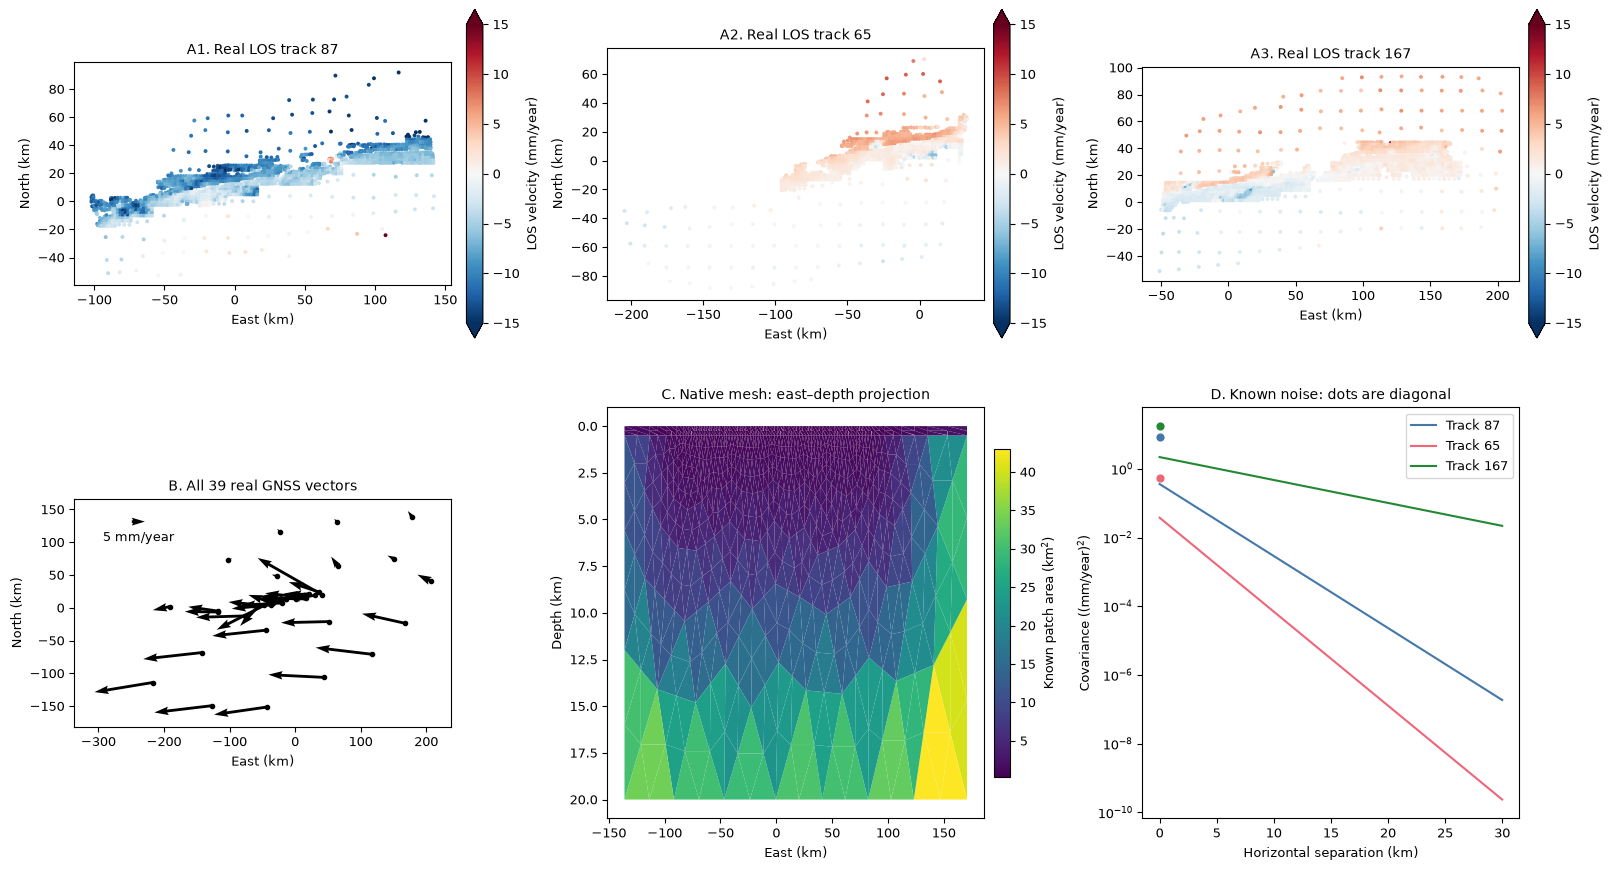

In [2]:
fig,axes=plt.subplots(2,3,figsize=(16,9),layout='constrained')
velocity_norm=TwoSlopeNorm(vmin=-15.,vcenter=0.,vmax=15.)
for i,name in enumerate(['87','65','167']):
 s=slice(tracks[i],tracks[i+1]);im=scatter_panel(axes[0,i],data['sar_xy'][s],data['sar_velocity'][s],f'A{i+1}. Real LOS track {name}',norm=velocity_norm,cmap='RdBu_r')
 colour(fig,im,axes[0,i],'LOS velocity (mm/year)',extend='both')
ax=axes[1,0];xy=data['gnss_xy'];v=data['gnss_velocity']
ax.scatter(xy[:,0],xy[:,1],s=9,color='black');q=ax.quiver(xy[:,0],xy[:,1],v[:,0],v[:,1],angles='xy',scale_units='xy',scale=.25,color='black')
vector_extent(ax,xy,v,.25)
ax.quiverkey(q,.17,.9,5.,'5 mm/year',coordinates='axes',labelpos='S');ax.set(xlabel='East (km)',ylabel='North (km)',title='B. All 39 real GNSS vectors');ax.set_aspect('equal')
centers=triangles.mean(axis=1)
patch_areas=.5*np.linalg.norm(np.cross(triangles[:,1]-triangles[:,0],triangles[:,2]-triangles[:,0]),axis=1)
im=fault_panel(axes[1,1],triangles,patch_areas,'C. Native mesh: east–depth projection')
colour(fig,im,axes[1,1],'Known patch area (km$^2$)')
distance=np.linspace(0,30,300);track_colors=['#4477aa','#ee6677','#228833']
for i,name in enumerate(['87','65','167']):
 axes[1,2].plot(distance,NOISE_SIGMA[i]**2*np.exp(-distance/NOISE_LENGTH_KM[i]),label='Track '+name,color=track_colors[i])
 axes[1,2].scatter([0],[NOISE_STD[i]**2],s=24,color=track_colors[i])
axes[1,2].set(xlabel='Horizontal separation (km)',ylabel='Covariance ((mm/year)$^2$)',title='D. Known noise: dots are diagonal',yscale='log');axes[1,2].legend()
emit(fig,'figure01_real_acquisition')

## 3. Physics: explicit elastic columns and dimensional closure

For uniform patch rates $s$, basin coefficient $a$ and datums $c$,
$$d=Gs+ba+Tc+\epsilon.$$
Here $G$ is built afresh from local angular-dislocation equations and actual
geometry. Each rectangular patch is exactly the sum of two triangles. The
native observation vector has3,554entries, and the full model has1,305entries.

For triangle vertices $p_1,p_2,p_3$, normalize
$n=(p_2-p_1)\times(p_3-p_1)$ and enforce its positive-down component.
Project slip onto each directed edge's local basis, subtract the angular
responses at its two endpoints, rotate back and sum three edges. Unit slip
responses are projected onto each supplied LOS; GNSS selects east and north.
The Poisson ratio is0.25and the ground surface is traction free.

The fixed empirical basin shape is
$$b_{ENU}=-10^6\frac{(1-\nu)r^3(X,Y,h)^T}{\mu(X^2+Y^2+h^2)^{3/2}}.$$
The horizontal offsets $X,Y$, depth $h=3000$m and radius $r=6000$m are in
metres, $\nu=0.25$, and $\mu=30$GPa. Its units are mm/kPa:1000mm/m times
1000Pa/kPa. The source's numeric coefficient therefore corresponds formally
to kPa/year, despite its MPa print label. Radius exceeds depth, so this is an
empirical subsidence basis and cannot establish genuine geological pressure.

The following source/fresh unit-response comparison includes every pixel of
each track for the eastern rectangular patch, represented by two exact
triangles locally and by the original Okada formula upstream. Signed differences have symmetric
limits and are numerical parity evidence, not evidence of physical accuracy.

Fresh full operator: (3554, 1305) seconds: 25.38143399999535 maximum absolute source difference: 5.545060938194624e-13


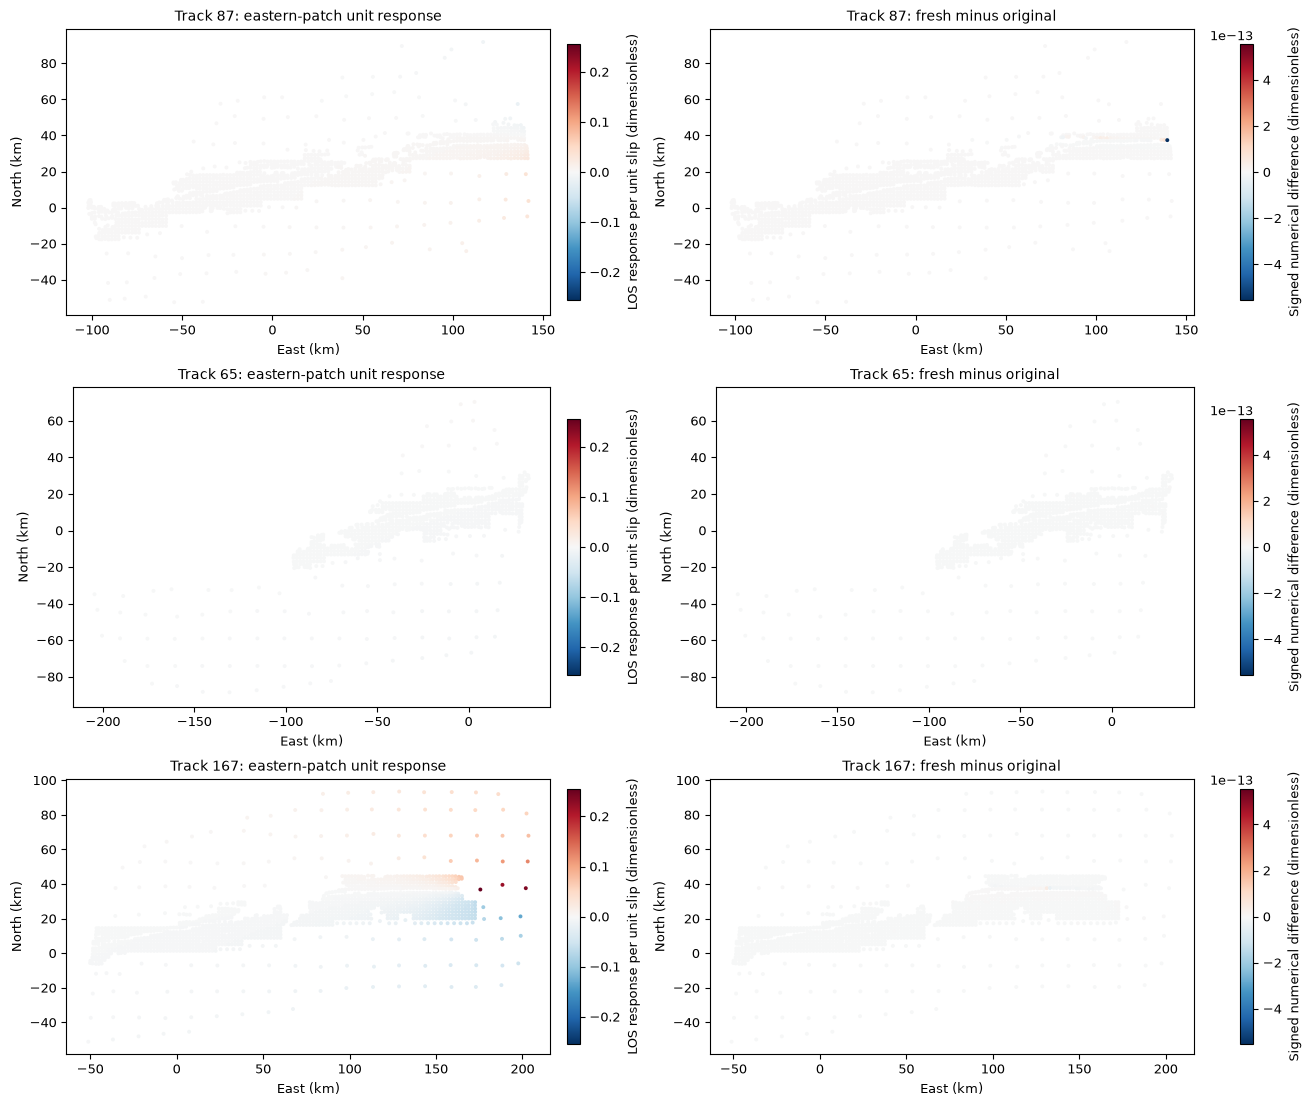

In [3]:
operator_started=time.perf_counter()
A,d,Cd,Cm=assemble_problem(data)
operator_seconds=time.perf_counter()-operator_started
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:
 original_A=z['_green'].copy()
with np.load(ROOT/'notebooks/reference_outputs/original_comparisons.npz',allow_pickle=False) as z:
 original={key.removeprefix('original_'):z[key].copy() for key in z.files}
print('Fresh full operator:',A.shape,'seconds:',operator_seconds,'maximum absolute source difference:',np.max(abs(A-original_A)))
patch=1297
fig,axes=plt.subplots(3,2,figsize=(13,11),layout='constrained')
unit_norm=signed_norm(A[:3476,patch]);difference= A[:3476,patch]-original_A[:3476,patch]
diff_norm=signed_norm(difference,fallback=1e-18)
for i,name in enumerate(['87','65','167']):
 s=slice(tracks[i],tracks[i+1])
 im=scatter_panel(axes[i,0],data['sar_xy'][s],A[s,patch],f'Track {name}: eastern-patch unit response',unit_norm,'RdBu_r')
 colour(fig,im,axes[i,0],'LOS response per unit slip (dimensionless)')
 im=scatter_panel(axes[i,1],data['sar_xy'][s],difference[s],f'Track {name}: fresh minus original',diff_norm,'RdBu_r')
 colour(fig,im,axes[i,1],'Signed numerical difference (dimensionless)')
emit(fig,'figure02_elastic_operator_parity')
noise_factor=cho_factor(Cd,lower=True)
def wrms(model,observed=d):
 r=observed-A@model
 return float(np.sqrt(r@cho_solve(noise_factor,r)/len(r)))

## 4. Method: conditional Gaussian priors, nonnegativity and deep equality

For the full operator $A=[G\;b\;T]$ and model $m=(s,a,c)$, minimize
$$J(m)=\tfrac12(Am-d)^TC_d^{-1}(Am-d)+\tfrac12(m-m_0)^TC_m^{-1}(m-m_0).$$
The observation covariance is $C_d$ and prior covariance is $C_m$.
For main-patch center separations $H_{ij},V_{ij}$, horizontal and vertical in km,
$$C_m(i,j)=\frac{(20\ell_0)^2}{\ell_x\ell_z}
\exp\left(-\frac{H_{ij}}{2\ell_x}-\frac{V_{ij}}{2\ell_z}\right),
\qquad \ell_x=10\ \mathrm{km},\quad\ell_z=1\ \mathrm{km}.$$
Each center is the arithmetic mean of its three vertices. For each coordinate,
divide the span of its distinct center values by their count; $\ell_0$ is the
norm of these three spacings in km. The amplitude20is in mm/year. Other
original variances are100for each deep rate,0.01for each remote rate,and1for
the basin coefficient and each datum,in their respective squared units.
All prior cross-block covariances are zero.
GLS has prior mean zero. Both NNLS groups instead give all five datum offsets
prior mean−100mm/year, with all other means zero; they impose $m-m_0\ge0$.
Thus GLS versus NNLS changes both the constraint and the datum prior.

With $LL^T=C_d^{-1}$ and $MM^T=C_m^{-1}$, solve NNLS for
$$F=\begin{bmatrix}L^TA\\M^T\end{bmatrix},\quad
q=\begin{bmatrix}L^T(d-Am_0)\\0\end{bmatrix},\quad
z=\arg\min_{z\ge0}\|Fz-q\|_2,\quad m=z+m_0.$$
The final group sums the five deep columns, assigns the shared variance100
(mm/year)$^2$, solves1,301variables, and maps the one rate back to all five
deep patches. The main fault still has1,292independent spatial outputs.
All three full fresh solves below use cleaned modules and the bound data.

gls {'fresh_seconds': 7.631432099995436, 'fresh_weighted_RMS': 1.0401931490635277, 'original_weighted_RMS': 1.0401931490635277, 'main_source_parity': {'ncc': 1.0, 'nrmse': 2.558050313609399e-14}}


nnls {'fresh_seconds': 14.569619399990188, 'fresh_weighted_RMS': 1.1777119541998633, 'original_weighted_RMS': 1.1777119541998662, 'main_source_parity': {'ncc': 0.9999999999999999, 'nrmse': 1.9631228633123174e-13}}


tied_nnls {'fresh_seconds': 14.44732049999584, 'fresh_weighted_RMS': 1.180939643521533, 'original_weighted_RMS': 1.180939643521534, 'main_source_parity': {'ncc': 1.0, 'nrmse': 1.884461669703111e-13}}


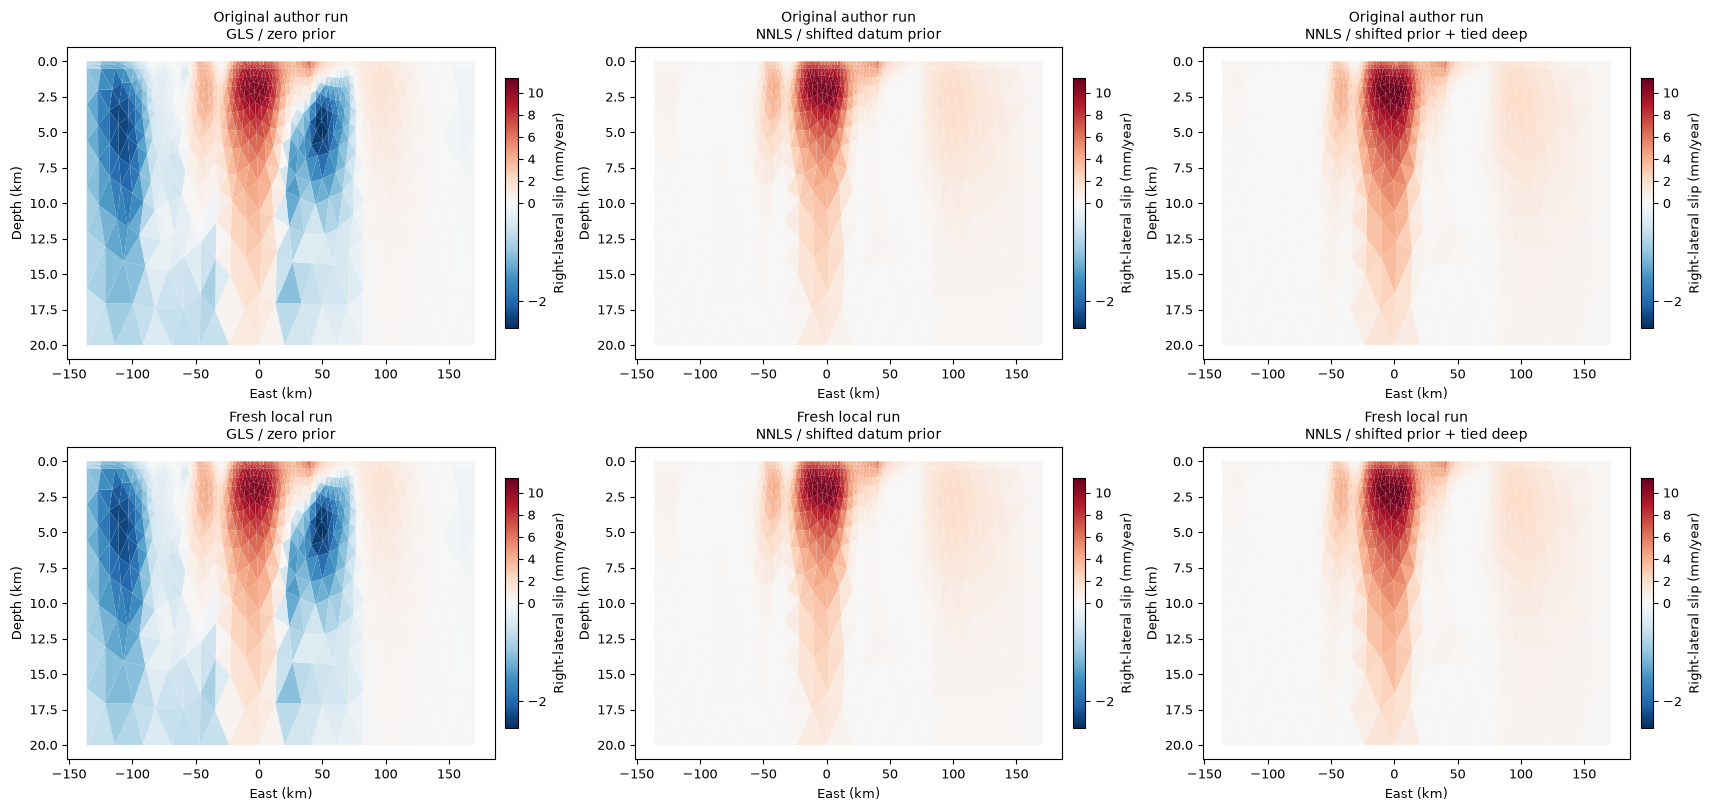

In [4]:
fresh={};diagnostics={};parity={}
for method in ['gls','nnls','tied_nnls']:
 fresh[method],diagnostics[method]=solve_system(A,d,Cd,Cm,method=method)
 parity[method]=reference_metrics(fresh[method][:1292],original[method][:1292])
 print(method,{'fresh_seconds':diagnostics[method]['runtime_seconds'],'fresh_weighted_RMS':wrms(fresh[method]),'original_weighted_RMS':wrms(original[method]),'main_source_parity':parity[method]})
all_main=np.concatenate([m[:1292] for m in [*original.values(),*fresh.values()]])
field_norm=TwoSlopeNorm(vcenter=0,vmin=min(-1e-8,float(all_main.min())),vmax=float(all_main.max()))
fig,axes=plt.subplots(2,3,figsize=(17,8),layout='constrained')
names=['GLS / zero prior','NNLS / shifted datum prior','NNLS / shifted prior + tied deep']
for j,(method,name) in enumerate(zip(fresh,names)):
 for row,(group,label) in enumerate([(original,'Original author run'),(fresh,'Fresh local run')]):
  im=fault_panel(axes[row,j],triangles,group[method][:1292],label+'\n'+name,norm=field_norm,cmap='RdBu_r')
  colour(fig,im,axes[row,j],'Right-lateral slip (mm/year)')
emit(fig,'figure03_all_native_inverse_comparisons')

## 5. Results: fitted observations, complete outputs and strict evaluation

The images above use the actual native triangles in east–depth projection;
the forward calculation uses their full curved3Dgeometry. The next figure
shows fresh predictions and signed residuals on all three tracks, followed
by complete GNSS observations/predictions and residual vectors. Display windows
are ±15mm/year for predicted LOS and ±8mm/year for signed LOS residuals;
colorbar triangles mark saturation and every value remains in the saved data. Residual
structure remains visible: agreement with the selected method is not proof
that the homogeneous elastic model captures every geological contribution.

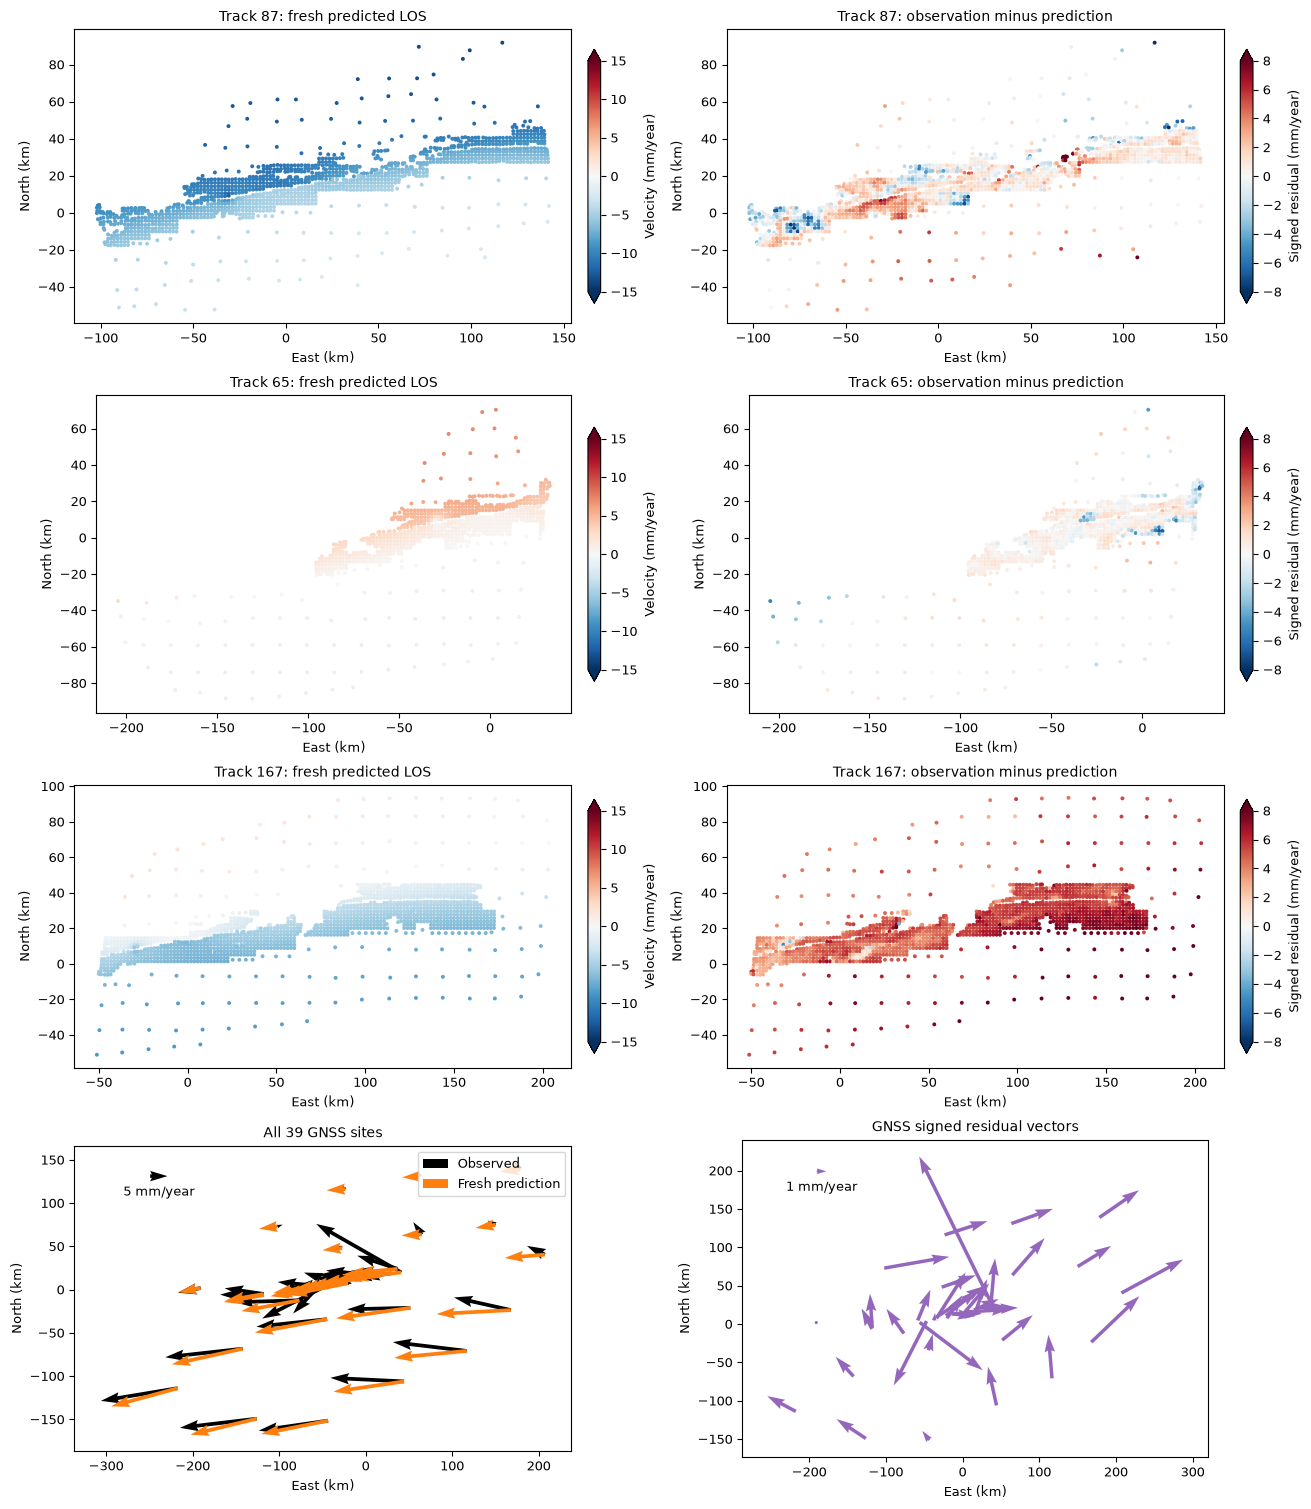

{'status': 'pass',
 'passed': True,
 'metrics': {'main_slip_ncc': 1.0,
  'main_slip_nrmse': 1.884461669703111e-13,
  'deep_slip_maxabs': 2.3803181647963356e-13,
  'east_slip_maxabs': 3.656797087359109e-15,
  'west_slip_maxabs': 8.257283745649602e-15,
  'basin_coefficient_maxabs': 6.750155989720952e-14,
  'datum0_maxabs': 2.842170943040401e-14,
  'datum1_maxabs': 1.4210854715202004e-14,
  'datum2_maxabs': 1.4210854715202004e-14,
  'datum3_maxabs': 9.947598300641403e-14,
  'datum4_maxabs': 1.4210854715202004e-13,
  'observation_weighted_rms': 1.1809396435215247},
 'thresholds': {'main_slip_ncc': {'comparison': '>=',
   'boundary': 0.9999999999999787},
  'main_slip_nrmse': {'comparison': '<=', 'boundary': 8.797334907099953e-09},
  'observation_weighted_rms': {'comparison': '<=',
   'boundary': 1.2399866256976022},
  'deep_slip_maxabs': {'comparison': '<=', 'boundary': 2.0164389624710566e-07},
  'east_slip_maxabs': {'comparison': '<=', 'boundary': 1.894024119833415e-09},
  'west_slip_maxab

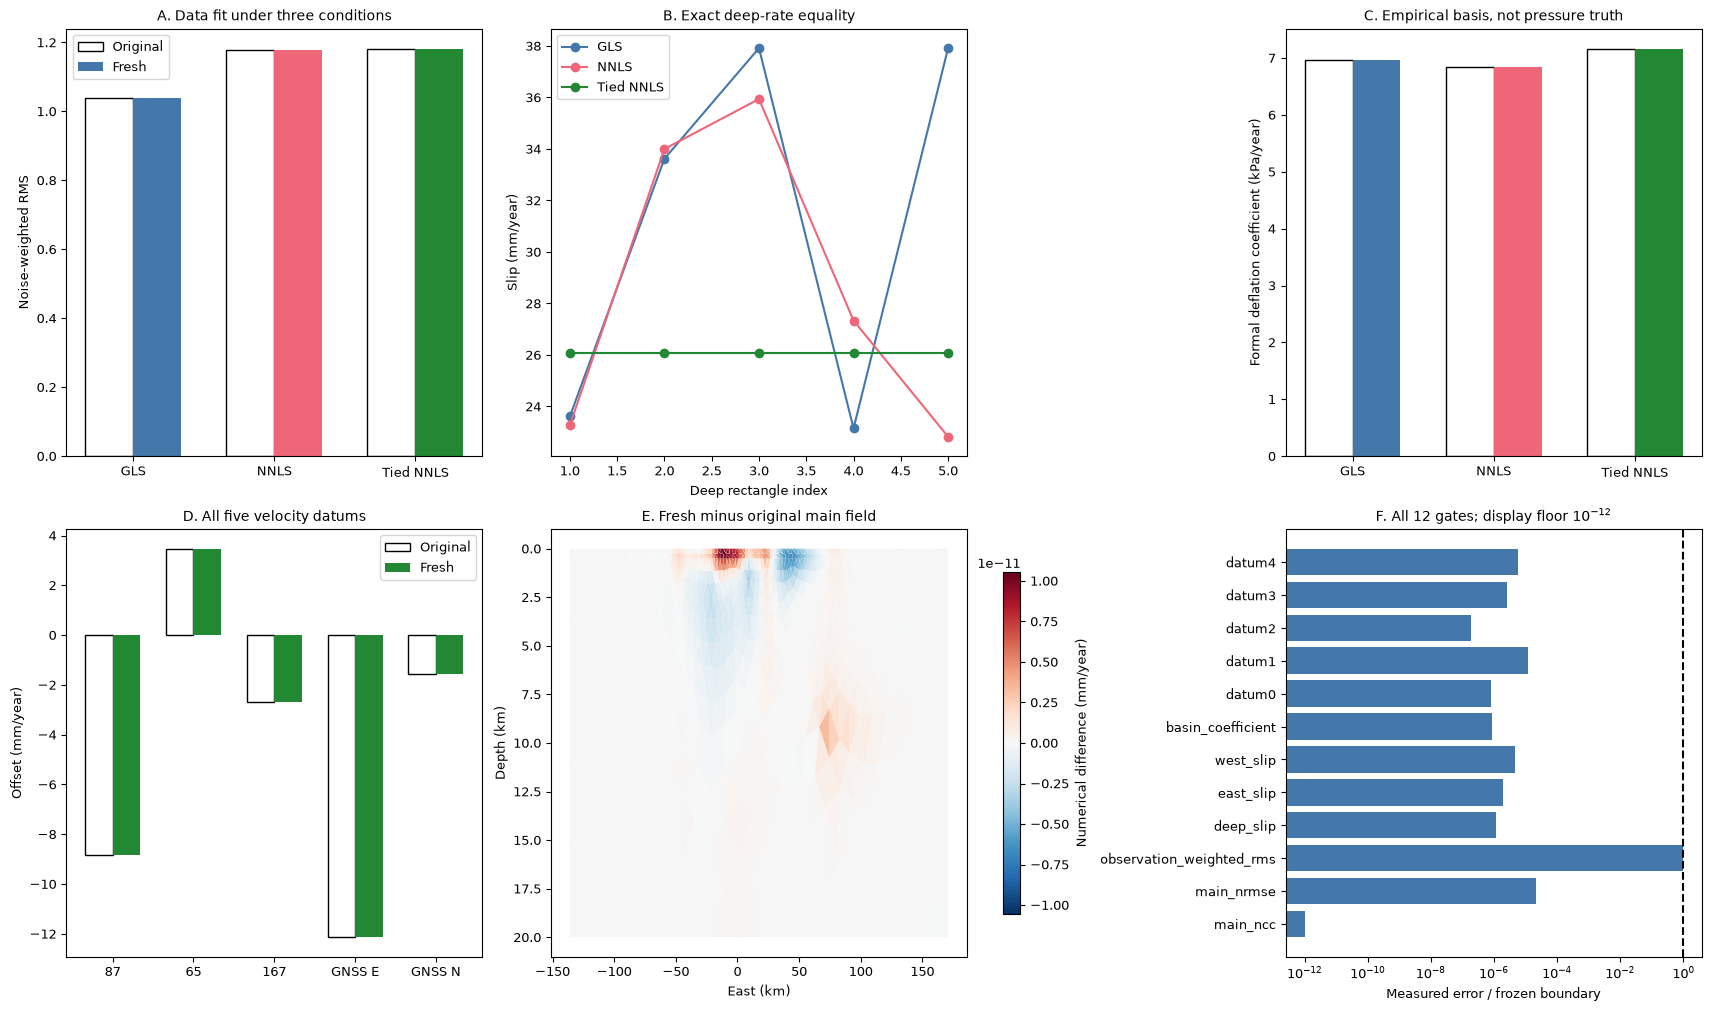

In [5]:
model=fresh['tied_nnls'];predicted=A@model;residual=d-predicted
fig,axes=plt.subplots(4,2,figsize=(13,15),layout='constrained')
prediction_norm=TwoSlopeNorm(vmin=-15.,vcenter=0.,vmax=15.)
residual_norm=TwoSlopeNorm(vmin=-8.,vcenter=0.,vmax=8.)
for i,name in enumerate(['87','65','167']):
 s=slice(tracks[i],tracks[i+1])
 im=scatter_panel(axes[i,0],data['sar_xy'][s],predicted[s],f'Track {name}: fresh predicted LOS',prediction_norm,'RdBu_r')
 colour(fig,im,axes[i,0],'Velocity (mm/year)',extend='both')
 im=scatter_panel(axes[i,1],data['sar_xy'][s],residual[s],f'Track {name}: observation minus prediction',residual_norm,'RdBu_r')
 colour(fig,im,axes[i,1],'Signed residual (mm/year)',extend='both')
xy=data['gnss_xy'];observed=data['gnss_velocity'];fitted=predicted[3476:].reshape(2,39).T;error=observed-fitted
for ax in axes[-1]:ax.set(xlabel='East (km)',ylabel='North (km)');ax.set_aspect('equal')
q=axes[3,0].quiver(xy[:,0],xy[:,1],observed[:,0],observed[:,1],angles='xy',scale_units='xy',scale=.25,color='black',label='Observed')
axes[3,0].quiver(xy[:,0],xy[:,1],fitted[:,0],fitted[:,1],angles='xy',scale_units='xy',scale=.25,color='tab:orange',label='Fresh prediction')
vector_extent(axes[3,0],np.concatenate([xy,xy]),np.concatenate([observed,fitted]),.25)
axes[3,0].quiverkey(q,.17,.9,5.,'5 mm/year',coordinates='axes',labelpos='S');axes[3,0].legend();axes[3,0].set_title('All 39 GNSS sites')
q=axes[3,1].quiver(xy[:,0],xy[:,1],error[:,0],error[:,1],angles='xy',scale_units='xy',scale=.08,color='tab:purple')
vector_extent(axes[3,1],xy,error,.08)
axes[3,1].quiverkey(q,.17,.9,1.,'1 mm/year',coordinates='axes',labelpos='S');axes[3,1].set_title('GNSS signed residual vectors')
emit(fig,'figure04_full_observation_residuals')
np.savez_compressed(ROOT/'output/reconstruction.npz',**output_arrays(model))
judge=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],cwd=ROOT,shell=False,capture_output=True,text=True)
assert judge.returncode==0,(judge.stdout,judge.stderr)
judge_report=json.loads((ROOT/'output/judge_report.json').read_text())
display(judge_report)
fig,axes=plt.subplots(2,3,figsize=(17,10),layout='constrained')
methods=list(fresh);x=np.arange(3)
axes[0,0].bar(x-.17,[wrms(original[k]) for k in methods],.34,color='white',edgecolor='black',label='Original')
axes[0,0].bar(x+.17,[wrms(fresh[k]) for k in methods],.34,color=['#4477aa','#ee6677','#228833'],label='Fresh')
axes[0,0].set(xticks=x,xticklabels=['GLS','NNLS','Tied NNLS'],ylabel='Noise-weighted RMS',title='A. Data fit under three conditions');axes[0,0].legend()
for method,name,color in zip(methods,['GLS','NNLS','Tied NNLS'],['#4477aa','#ee6677','#228833']):axes[0,1].plot(np.arange(1,6),fresh[method][1292:1297],marker='o',label=name,color=color)
axes[0,1].set(xlabel='Deep rectangle index',ylabel='Slip (mm/year)',title='B. Exact deep-rate equality');axes[0,1].legend()
axes[0,2].bar(x-.17,[original[k][1299] for k in methods],.34,color='white',edgecolor='black',label='Original')
axes[0,2].bar(x+.17,[fresh[k][1299] for k in methods],.34,color=['#4477aa','#ee6677','#228833'],label='Fresh')
axes[0,2].set(xticks=x,xticklabels=['GLS','NNLS','Tied NNLS'],ylabel='Formal deflation coefficient (kPa/year)',title='C. Empirical basis, not pressure truth')
axes[1,0].bar(np.arange(5)-.17,original['tied_nnls'][1300:],.34,color='white',edgecolor='black',label='Original')
axes[1,0].bar(np.arange(5)+.17,model[1300:],.34,color='#228833',label='Fresh')
axes[1,0].set(xticks=np.arange(5),xticklabels=['87','65','167','GNSS E','GNSS N'],ylabel='Offset (mm/year)',title='D. All five velocity datums');axes[1,0].legend()
field_difference=model[:1292]-original['tied_nnls'][:1292]
im=fault_panel(axes[1,1],triangles,field_difference,'E. Fresh minus original main field',signed_norm(field_difference),'RdBu_r');colour(fig,im,axes[1,1],'Numerical difference (mm/year)')
ratios={}
for key,t in judge_report['thresholds'].items():
 value=judge_report['metrics'][key]
 ratios[key]=(1.-value)/(1.-t['boundary']) if key=='main_slip_ncc' else value/t['boundary']
keys=list(ratios);axes[1,2].barh(np.arange(len(keys)),[max(ratios[k],1e-12) for k in keys],color='#4477aa');axes[1,2].set_xscale('log');axes[1,2].axvline(1,color='black',linestyle='--');axes[1,2].set(yticks=np.arange(len(keys)),yticklabels=[k.replace('_maxabs','').replace('main_slip','main') for k in keys],xlabel='Measured error / frozen boundary',title='F. All 12 gates; display floor $10^{-12}$')
emit(fig,'figure05_constraints_units_and_all_gates')

## 6. Sensitivity and conclusion: a conditional image, not hidden truth

We now recompute the full inverse after removing radar noise correlations,
halving/doubling the entire prior covariance, and adding a new correlated
velocity perturbation. The latter uses the tested generator, seed20261022,
and covariance0.15²times the known observation covariance. It is a diagnostic
observation draw, not bound benchmark data or an independent truth field.
Every plotted alternative is a fresh solve. Changes quantify sensitivity to
assumptions and observations; no posterior-uncertainty claim is inferred from
one perturbation draw.

{'Baseline': {'weighted_RMS_on_original_data': 1.180939643521533,
  'RMS_main_change_mm_per_year': 0.0,
  'main_mean_mm_per_year': 2.275959978006295},
 'Diagonal noise': {'weighted_RMS_on_original_data': 1.1181254468513513,
  'RMS_main_change_mm_per_year': 0.20449183550190803,
  'main_mean_mm_per_year': 2.2214663762584657},
 'Half prior covariance': {'weighted_RMS_on_original_data': 1.4747505202706188,
  'RMS_main_change_mm_per_year': 0.4812257300617709,
  'main_mean_mm_per_year': 2.1813462260418843},
 'Double prior covariance': {'weighted_RMS_on_original_data': 1.0784674535975083,
  'RMS_main_change_mm_per_year': 0.5630830356573485,
  'main_mean_mm_per_year': 2.400189208761443},
 'Perturbed observations': {'weighted_RMS_on_original_data': 1.180055652228348,
  'RMS_main_change_mm_per_year': 0.031841873156632935,
  'main_mean_mm_per_year': 2.2698636414622366}}

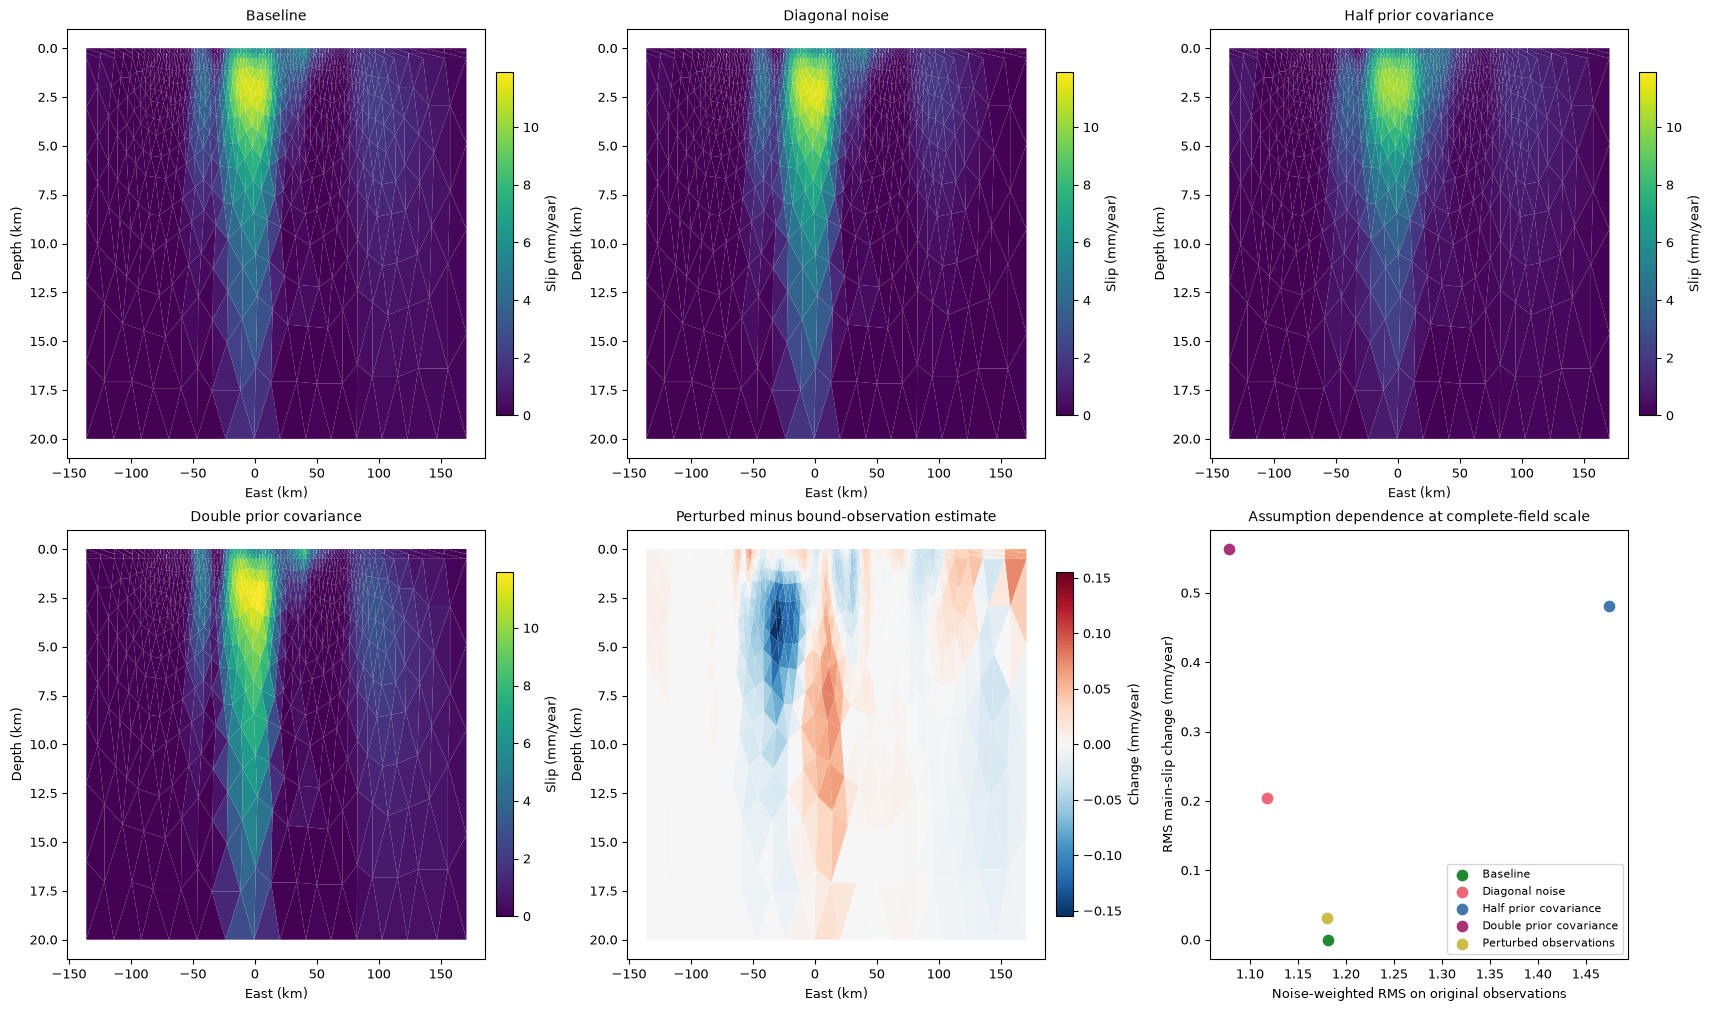

Fresh complete benchmark Judge: pass
Actual total computation seconds: 157.80635739999707


In [6]:
sensitivity={'Baseline':model};sensitivity_details={'Baseline':diagnostics['tied_nnls']}
diagonal_cd=build_data_covariance(data,diagonal=True)
sensitivity['Diagonal noise'],sensitivity_details['Diagonal noise']=solve_system(A,d,diagonal_cd,Cm)
for scale,name in [(.5,'Half prior covariance'),(2.,'Double prior covariance')]:
 sensitivity[name],sensitivity_details[name]=solve_system(A,d,Cd,Cm*scale)
perturbed,noise=correlated_velocity_perturbation(data,Cd,seed=20261022,fraction=.15)
sensitivity['Perturbed observations'],sensitivity_details['Perturbed observations']=solve_system(A,observation_vector(perturbed),Cd,Cm)
sensitivity_metrics={name:{'weighted_RMS_on_original_data':wrms(m),'RMS_main_change_mm_per_year':float(np.sqrt(np.mean((m[:1292]-model[:1292])**2))),'main_mean_mm_per_year':float(np.mean(m[:1292]))} for name,m in sensitivity.items()}
display(sensitivity_metrics)
fig,axes=plt.subplots(2,3,figsize=(17,10),layout='constrained')
map_names=list(sensitivity)[:4]
norm=Normalize(vmin=0,vmax=max(np.max(sensitivity[k][:1292]) for k in map_names))
for ax,name in zip(axes.ravel()[:4],map_names):
 im=fault_panel(ax,triangles,sensitivity[name][:1292],name,norm=norm);colour(fig,im,ax,'Slip (mm/year)')
noise_change=sensitivity['Perturbed observations'][:1292]-model[:1292]
im=fault_panel(axes[1,1],triangles,noise_change,'Perturbed minus bound-observation estimate',signed_norm(noise_change),'RdBu_r');colour(fig,im,axes[1,1],'Change (mm/year)')
colors=['#228833','#ee6677','#4477aa','#aa3377','#ccbb44']
for color,(name,metrics) in zip(colors,sensitivity_metrics.items()):
 axes[1,2].scatter(metrics['weighted_RMS_on_original_data'],metrics['RMS_main_change_mm_per_year'],s=55,color=color,label=name)
axes[1,2].set(xlabel='Noise-weighted RMS on original observations',ylabel='RMS main-slip change (mm/year)',title='Assumption dependence at complete-field scale');axes[1,2].legend(fontsize=8)
emit(fig,'figure06_fresh_sensitivity_experiments')
numeric={'fault_triangles':triangles,'patch_area_km2':patch_areas,'sar_xy':data['sar_xy'],'sar_los':data['sar_los'],'sar_velocity':data['sar_velocity'],
 'sar_track_index':data['sar_track_index'],'gnss_xy':data['gnss_xy'],'gnss_observed':data['gnss_velocity'],
 'operator_unit_patch':A[:,patch],'original_operator_unit_patch':original_A[:,patch],
 'predicted':predicted,'signed_residual':residual,'perturbation_mm_per_year':noise,
 'known_covariance_distance_km':distance,'known_covariance_curves':np.array([s*s*np.exp(-distance/l) for s,l in zip(NOISE_SIGMA,NOISE_LENGTH_KM)])}
numeric.update({'original_'+k:v for k,v in original.items()});numeric.update({'fresh_'+k:v for k,v in fresh.items()})
numeric.update({'sensitivity_'+str(i):v for i,v in enumerate(sensitivity.values())})
summary={'environment':environment,'operator_seconds':operator_seconds,'full_notebook_computation_seconds':time.perf_counter()-started,
 'original_fresh_parity':parity,'fresh_diagnostics':{k:{q:v for q,v in detail.items() if not isinstance(v,np.ndarray)} for k,detail in diagnostics.items()},
 'judge':judge_report,'sensitivity':sensitivity_metrics,'sensitivity_order':list(sensitivity),'seed':20261022,
 'perturbation_fraction':.15,'unit_patch_index':patch,'unit_patch_kind':'east rectangle, exact two-triangle identity',
 'display_windows':{'LOS_mm_per_year':[-15,15],'LOS_residual_mm_per_year':[-8,8],'saturation_indicated_by_colourbar_extend':True},
 'raw_data_sha256':hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest(),
 'reference_kind':'independent original conditional method estimate, not subsurface truth',
 'basin_units':'formal kPa/year fixed empirical Mogi shape; not geological pressure truth'}
if FIGDIR:
 np.savez_compressed(FIGDIR/'numeric_sources.npz',**numeric)
 (FIGDIR/'experiment_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf-8')
print('Fresh complete benchmark Judge:',judge_report['status'])
print('Actual total computation seconds:',summary['full_notebook_computation_seconds'])

The complete local estimate passes every predeclared field and forward gate.
All three published-tutorial comparison groups were recomputed, and their
original and fresh results are identified separately. Remaining structured
residuals and the last sensitivity figure show why numerical reproduction
does not establish uniquely correct subsurface slip. The empirical basin
shape, homogeneous elasticity, fixed fault geometry and selected priors limit
the physical interpretation. Every required slip and nuisance quantity is
retained, including the weak remote fault rates and the five datums.